In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os
print(os.listdir('/content/drive/MyDrive/'))

['Colab Notebooks', '8.png', '2.png', '19.png', '18.png', '13.png', '20.png', '11.png', '3.png', '14.png', '9.png', '1.png', '17.png', '6.png', '16.png', '4.png', '15.png', '12.png', '10.png', '7.png', '5.png', 'jeux', 'JEUX', 'Byzantine_monograms', 'compare_models_whisper.py', 'Séance 7', 'exemples', 'JURAFSKY', 'ADMINISTRATIF', 'LIVRES', 'anglais', 'Blogs Mots&Pouvoir', 'sranga', 'CV', 'Memoire M1', 'Byzantine_monograms (1).tar', 'Byzantine_monograms.tar', 'bhai_classification', 'bhai_classification.zip', 'Rapport_OCR_Sawadogo_Diouhe_v2 (2).gdoc', 'Rapport_OCR_Sawadogo_Diouhe_v2 (1).gdoc', 'Rapport_OCR_Sawadogo_Diouhe_v2.gdoc', 'Sawadogo_Ezechiel_M1_LI_Translation_Tesniere (2).gdoc', 'Sawadogo_Ezechiel_M1_LI_Translation_Tesniere (1).gdoc', 'Sawadogo_Ezechiel_M1_LI_Translation_Tesniere.gdoc', 'SYNTHESE_COMPLETE_EXAM.md.gdoc']


In [3]:
print(os.listdir('/content/drive/MyDrive/bhai_classification/'))

['requirements.txt', 'README.md', '.venv', 'data', 'splits', 'results_v1', 'results']


In [4]:
print(os.listdir('/content/drive/MyDrive/bhai_classification/data/'))

['zacos.csv', 'adolfo.csv', 'Adolfo', 'Zacos']


In [5]:
# Cell 1 - Installation (Colab)
# If torchvision is already recent enough, this cell can be skipped.
!pip -q install -U torch torchvision scikit-learn matplotlib seaborn pandas

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.8/52.8 kB 5.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 8.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 530.7/530.7 MB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 366.1/366.1 MB 4.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 169.9/169.9 MB 7.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 196.5/196.5 MB 5.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.4/60.4 MB 14.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 423.1/423.1 MB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.7/10.7 MB 64.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.2/90.2 MB 9.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 96.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 214.1/214.1 MB 5.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2

In [74]:
# Cell 2 - Imports and global configuration
import os
import re
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image, ImageFile

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

import torchvision
from torchvision import transforms
from torchvision.transforms import InterpolationMode
from torchvision.models import (
    EfficientNet_B0_Weights,
    ConvNeXt_Tiny_Weights,
    ViT_B_16_Weights,
    efficientnet_b0,
    convnext_tiny,
    vit_b_16,
)

try:
    from torchvision.models import DeiT_Small_Patch16_224_Weights, deit_small_patch16_224
    HAS_DEIT = True
except ImportError:
    HAS_DEIT = False

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

ImageFile.LOAD_TRUNCATED_IMAGES = True

SEED = 42
IMG_SIZE = 224
BATCH_SIZE = 32
NUM_WORKERS = 2
EPOCHS = 20
LR = 3e-4
WEIGHT_DECAY = 1e-4
LABEL_SMOOTHING = 0.05
EARLY_STOPPING_PATIENCE = 5

DATA_ROOT = "/content/drive/MyDrive/bhai_classification/data"
ZACOS_CSV = "/content/drive/MyDrive/bhai_classification/data/zacos.csv"
ADOLFO_CSV = "/content/drive/MyDrive/bhai_classification/data/adolfo.csv"

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"

print("torch:", torch.__version__)
print("torchvision:", torchvision.__version__)
print("device:", DEVICE)


torch: 2.11.0+cu130
torchvision: 0.26.0+cu130
device: cuda


In [35]:
import pandas as pd

zacos_csv = "/content/drive/MyDrive/bhai_classification/data/zacos.csv"
adolfo_csv = "/content/drive/MyDrive/bhai_classification/data/adolfo.csv"

zacos_df = pd.read_csv(zacos_csv)
adolfo_df = pd.read_csv(adolfo_csv)

print("Zacos columns:", list(zacos_df.columns))
display(zacos_df.head())

print("Adolfo columns:", list(adolfo_df.columns))
display(adolfo_df.head())


Zacos columns: ['filename', 'quality_label', 'remarks']


,filename,quality_label,remarks
0,Seyrig 012_A.jpg,2,NaN
1,Seyrig 016_A.jpg,2,NaN
2,Seyrig 019_A.jpg,1,NaN
3,Seyrig 020_A.jpg,2,NaN
4,Seyrig 021_A.jpg,0,NaN


Adolfo columns: ['monogram_id', 'quality_label']


,monogram_id,quality_label
0,1__5.249__699,1
1,2__3.8__466,1
2,3__3.8__466,1
3,4__5.2__538,2
4,5__4.4__30,1


In [36]:
VALID_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}

def resolve_data_dirs(data_root):
    data_root = Path(data_root)
    if not data_root.exists():
        raise ValueError(f"Dataset root not found: {data_root}")

    dirs_by_lower_name = {
        p.name.lower(): p for p in data_root.iterdir() if p.is_dir()
    }

    expected = ["zacos", "adolfo"]
    found_dirs = []

    for name in expected:
        if name in dirs_by_lower_name:
            found_dirs.append(dirs_by_lower_name[name])
        else:
            print(f"[WARN] Sous-dossier manquant: {name}")

    if not found_dirs:
        raise ValueError(f"Aucun dossier 'zacos' ou 'adolfo' trouvé dans {data_root}")

    return found_dirs

DATA_DIRS = resolve_data_dirs(DATA_ROOT)
print(DATA_DIRS)


[PosixPath('/content/drive/MyDrive/bhai_classification/data/Zacos'), PosixPath('/content/drive/MyDrive/bhai_classification/data/Adolfo')]


In [37]:
# Cell 3 - Reproducibility helpers
def set_seed(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = False
    torch.backends.cudnn.benchmark = True


set_seed(SEED)

In [38]:
# Cell 4 - Label extraction from filenames
from pathlib import Path
import re

def extract_label_from_filename(path: str) -> str:
    filename = Path(path).name
    stem = Path(path).stem

    # Adolfo: 100__5.76-77__335.jpg -> 5.76-77
    if "__" in filename:
        parts = stem.split("__")
        if len(parts) >= 3:
            return parts[1].strip()

    # Zacos: Seyrig 012_A.jpg -> A
    m = re.search(r"_([A-Za-z0-9]+)$", stem)
    if m:
        return m.group(1).strip()

    return stem.strip()




In [39]:
df = collect_samples(DATA_DIRS)

print(df[["path", "label", "source"]].head(20))
print("Nombre de classes :", df["label"].nunique())
print(df["label"].value_counts().head(30))



                                                 path label source
0   /content/drive/MyDrive/bhai_classification/dat...     A  Zacos
1   /content/drive/MyDrive/bhai_classification/dat...     A  Zacos
2   /content/drive/MyDrive/bhai_classification/dat...     A  Zacos
3   /content/drive/MyDrive/bhai_classification/dat...     B  Zacos
4   /content/drive/MyDrive/bhai_classification/dat...     B  Zacos
5   /content/drive/MyDrive/bhai_classification/dat...     A  Zacos
6   /content/drive/MyDrive/bhai_classification/dat...     A  Zacos
7   /content/drive/MyDrive/bhai_classification/dat...     B  Zacos
8   /content/drive/MyDrive/bhai_classification/dat...     B  Zacos
9   /content/drive/MyDrive/bhai_classification/dat...     A  Zacos
10  /content/drive/MyDrive/bhai_classification/dat...     B  Zacos
11  /content/drive/MyDrive/bhai_classification/dat...     A  Zacos
12  /content/drive/MyDrive/bhai_classification/dat...     A  Zacos
13  /content/drive/MyDrive/bhai_classification/dat...     A  Z

In [40]:
from pathlib import Path

for folder in DATA_DIRS:
    print("\nDOSSIER:", folder)
    files = sorted([p.name for p in Path(folder).glob("*") if p.is_file()])
    print(files[:10])



DOSSIER: /content/drive/MyDrive/bhai_classification/data/Zacos
['Seyrig 012_A.jpg', 'Seyrig 016_A.jpg', 'Seyrig 019_A.jpg', 'Seyrig 020_A.jpg', 'Seyrig 021_A.jpg', 'Seyrig 027_A.jpg', 'Seyrig 028_A.jpg', 'Seyrig 029_B.jpg', 'Seyrig 030_A.jpg', 'Seyrig 030_B.jpg']

DOSSIER: /content/drive/MyDrive/bhai_classification/data/Adolfo
['100__5.75__215.jpg', '101__5.76-77__335.jpg', '102__5.78__169.jpg', '103__5.79__715.jpg', '104__5.80__381.jpg', '105__4.11__63.jpg', '106__5.81__189.jpg', '107__5.254__435.jpg', '108__5.82__373.jpg', '109__5.10__521.jpg']


In [41]:
def collect_images_df(data_dirs):
    rows = []
    for data_dir in data_dirs:
        data_dir = Path(data_dir)
        source = data_dir.name

        for path in data_dir.rglob("*"):
            if path.is_file() and path.suffix.lower() in VALID_EXTS:
                rows.append({
                    "path": str(path),
                    "filename": path.name,
                    "stem": path.stem,
                    "source": source,
                })

    df = pd.DataFrame(rows)
    if len(df) == 0:
        raise ValueError("Aucune image trouvée.")
    return df


def load_annotations():
    zacos_ann = pd.read_csv(ZACOS_CSV)
    adolfo_ann = pd.read_csv(ADOLFO_CSV)

    zacos_ann["source"] = "Zacos"
    adolfo_ann["source"] = "Adolfo"

    zacos_ann = zacos_ann.rename(columns={
        "filename": "join_key",
        "quality_label": "quality_label"
    })[["source", "join_key", "quality_label"]]

    adolfo_ann["join_key"] = adolfo_ann["monogram_id"].astype(str).str.strip() + ".jpg"
    adolfo_ann = adolfo_ann[["source", "join_key", "quality_label"]]

    ann_df = pd.concat([zacos_ann, adolfo_ann], ignore_index=True)
    ann_df["quality_label"] = ann_df["quality_label"].astype(int)
    ann_df["label"] = ann_df["quality_label"].apply(lambda x: f"M{x}")
    return ann_df


images_df = collect_images_df(DATA_DIRS)
ann_df = load_annotations()

images_df["join_key"] = images_df["filename"]
df = images_df.merge(ann_df, on=["source", "join_key"], how="inner")

print("Total images after merge:", len(df))
print("Classes:", sorted(df["label"].unique()))
print(df["label"].value_counts())
display(df.head())



Total images after merge: 625
Classes: ['M0', 'M1', 'M2', 'M3']
label
M1    272
M2    244
M0     80
M3     29
Name: count, dtype: int64


,path,filename,stem,source,join_key,quality_label,label
0,/content/drive/MyDrive/bhai_classification/dat...,Tatish 2612_A.jpg,Tatish 2612_A,Zacos,Tatish 2612_A.jpg,2,M2
1,/content/drive/MyDrive/bhai_classification/dat...,Tatish 3028_A.jpg,Tatish 3028_A,Zacos,Tatish 3028_A.jpg,1,M1
2,/content/drive/MyDrive/bhai_classification/dat...,Tatish 3041_A.jpg,Tatish 3041_A,Zacos,Tatish 3041_A.jpg,0,M0
3,/content/drive/MyDrive/bhai_classification/dat...,Tatish 3041_B.jpg,Tatish 3041_B,Zacos,Tatish 3041_B.jpg,0,M0
4,/content/drive/MyDrive/bhai_classification/dat...,Seyrig 032_B.jpg,Seyrig 032_B,Zacos,Seyrig 032_B.jpg,2,M2


In [42]:
zacos_images = images_df[images_df["source"] == "Zacos"].copy()
adolfo_images = images_df[images_df["source"] == "Adolfo"].copy()

zacos_ann = ann_df[ann_df["source"] == "Zacos"].copy()
adolfo_ann = ann_df[ann_df["source"] == "Adolfo"].copy()

print("Zacos images:", len(zacos_images))
print("Zacos annotations:", len(zacos_ann))
print("Zacos matched:", len(df[df["source"] == "Zacos"]))

print("Adolfo images:", len(adolfo_images))
print("Adolfo annotations:", len(adolfo_ann))
print("Adolfo matched:", len(df[df["source"] == "Adolfo"]))

display(df["label"].value_counts().sort_index().to_frame("count"))


Zacos images: 276
Zacos annotations: 275
Zacos matched: 275
Adolfo images: 351
Adolfo annotations: 350
Adolfo matched: 350


,count
label,
M0,80
M1,272
M2,244
M3,29


,count
label,
M1,272
M2,244
M0,80
M3,29


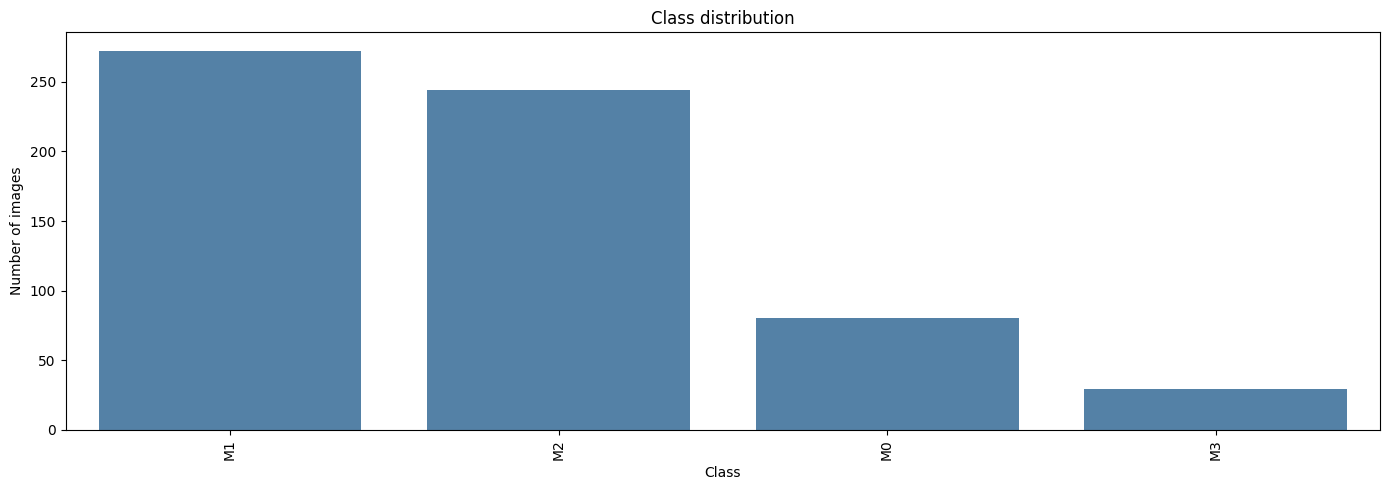

Smallest class size: 29


In [43]:
# Cell 6 - Quick dataset sanity checks
class_counts = df["label"].value_counts().sort_values(ascending=False)
display(class_counts.to_frame("count").head(30))

plt.figure(figsize=(14, 5))
sns.barplot(x=class_counts.index, y=class_counts.values, color="steelblue")
plt.xticks(rotation=90)
plt.title("Class distribution")
plt.ylabel("Number of images")
plt.xlabel("Class")
plt.tight_layout()
plt.show()

min_count = class_counts.min()
print("Smallest class size:", min_count)
if min_count < 3:
    print(
        "[WARN] At least one class has fewer than 3 images. "
        "A stratified train/val/test split may fail. Add images or merge rare classes."
    )


In [44]:
# Cell 7 - Train/val/test split
train_df, test_df = train_test_split(
    df,
    test_size=0.15,
    stratify=df["label"],
    random_state=SEED,
)

relative_val_size = 0.15 / 0.85
train_df, val_df = train_test_split(
    train_df,
    test_size=relative_val_size,
    stratify=train_df["label"],
    random_state=SEED,
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print(f"Train: {len(train_df)}")
print(f"Val:   {len(val_df)}")
print(f"Test:  {len(test_df)}")


Train: 437
Val:   94
Test:  94


In [45]:
# Cell 8 - Label encoding
classes = sorted(df["label"].unique())
class_to_idx = {cls: idx for idx, cls in enumerate(classes)}
idx_to_class = {idx: cls for cls, idx in class_to_idx.items()}
num_classes = len(classes)

for split_df in [train_df, val_df, test_df]:
    split_df["target"] = split_df["label"].map(class_to_idx)

print("Classes finales:", classes)
print("Nombre de classes:", num_classes)



Classes finales: ['M0', 'M1', 'M2', 'M3']
Nombre de classes: 4


In [46]:
print(df[["filename", "source", "quality_label", "label"]].sample(10, random_state=42))


                 filename  source  quality_label label
447     258__3.4__157.jpg  Adolfo              1    M1
485   290__5.211__432.jpg  Adolfo              1    M1
215     Tatish 3044_A.jpg   Zacos              1    M1
212     Tatish 2954_A.jpg   Zacos              2    M2
480    278__8.40__436.jpg  Adolfo              0    M0
515     320__5.94__94.jpg  Adolfo              1    M1
163     Tatish 2767_A.jpg   Zacos              2    M2
77      Tatish 2316_B.jpg   Zacos              2    M2
527  32__5.30-31__623.jpg  Adolfo              2    M2
145     Tatish 2694_A.jpg   Zacos              2    M2


In [47]:
print(df["label"].value_counts().sort_index())
print(df.groupby(["source", "label"]).size().unstack(fill_value=0))


label
M0     80
M1    272
M2    244
M3     29
Name: count, dtype: int64
label   M0   M1   M2  M3
source                  
Adolfo  48  159  125  18
Zacos   32  113  119  11


In [76]:
def build_transforms(weights):
    if weights is not None and hasattr(weights, "meta"):
        mean = weights.meta["mean"] if "mean" in weights.meta else [0.485, 0.456, 0.406]
        std = weights.meta["std"] if "std" in weights.meta else [0.229, 0.224, 0.225]
    else:
        mean = [0.485, 0.456, 0.406]
        std = [0.229, 0.224, 0.225]

    train_tfms = transforms.Compose([
        transforms.Resize((IMG_SIZE, IMG_SIZE), interpolation=InterpolationMode.BICUBIC),
        transforms.RandomApply(
            [transforms.RandomAffine(degrees=8, translate=(0.05, 0.05), scale=(0.95, 1.05))],
            p=0.7,
        ),
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.RandomVerticalFlip(p=0.1),
        transforms.RandomApply([transforms.ColorJitter(brightness=0.15, contrast=0.15)], p=0.5),
        transforms.RandomApply([transforms.GaussianBlur(kernel_size=3, sigma=(0.1, 1.0))], p=0.15),
        transforms.ToTensor(),
        transforms.Normalize(mean=mean, std=std),
        transforms.RandomErasing(p=0.15, scale=(0.02, 0.10), ratio=(0.3, 3.3), value="random"),
    ])

    eval_tfms = transforms.Compose([
        transforms.Resize((IMG_SIZE, IMG_SIZE), interpolation=InterpolationMode.BICUBIC),
        transforms.ToTensor(),
        transforms.Normalize(mean=mean, std=std),
    ])
    return train_tfms, eval_tfms


In [50]:
# Cell 10 - Dataset class
class SealCharacterDataset(Dataset):
    def __init__(self, df, transform=None):
        self.df = df.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        image = Image.open(row["path"]).convert("RGB")
        if self.transform is not None:
            image = self.transform(image)
        target = int(row["target"])
        return image, target

In [75]:

# Cell 11 - Model factory
class DinoV2Classifier(nn.Module):
    def __init__(self, backbone, in_features, num_classes):
        super().__init__()
        self.backbone = backbone
        self.head = nn.Linear(in_features, num_classes)

    def forward(self, x):
        features = self.backbone(x)

        if isinstance(features, dict):
            if "x_norm_clstoken" in features:
                features = features["x_norm_clstoken"]
            elif "x_norm_patchtokens" in features:
                features = features["x_norm_patchtokens"].mean(dim=1)
            else:
                features = list(features.values())[0]

        return self.head(features)


def build_model(model_name: str, num_classes: int):
    if model_name == "efficientnet_b0":
        weights = EfficientNet_B0_Weights.DEFAULT
        model = efficientnet_b0(weights=weights)
        in_features = model.classifier[1].in_features
        model.classifier[1] = nn.Linear(in_features, num_classes)
        return model, weights

    if model_name == "convnext_tiny":
        weights = ConvNeXt_Tiny_Weights.DEFAULT
        model = convnext_tiny(weights=weights)
        in_features = model.classifier[2].in_features
        model.classifier[2] = nn.Linear(in_features, num_classes)
        return model, weights

    if model_name == "vit_b_16":
        weights = ViT_B_16_Weights.DEFAULT
        model = vit_b_16(weights=weights)
        in_features = model.heads.head.in_features
        model.heads.head = nn.Linear(in_features, num_classes)
        return model, weights

    if model_name == "dinov2_vits14":
        backbone = torch.hub.load("facebookresearch/dinov2", "dinov2_vits14")
        model = DinoV2Classifier(backbone, in_features=384, num_classes=num_classes)
        return model, None

    if model_name == "deit_small":
        if not HAS_DEIT:
            raise ImportError(
                "deit_small_patch16_224 is unavailable in this torchvision version. "
                "Update torchvision in Colab or use a newer runtime."
            )
        weights = DeiT_Small_Patch16_224_Weights.DEFAULT
        model = deit_small_patch16_224(weights=weights)
        in_features = model.head.in_features
        model.head = nn.Linear(in_features, num_classes)
        return model, weights

    raise ValueError(f"Unknown model: {model_name}")



In [52]:
# Cell 12 - DataLoaders
def make_loaders(weights):
    train_tfms, eval_tfms = build_transforms(weights)

    train_ds = SealCharacterDataset(train_df, transform=train_tfms)
    val_ds = SealCharacterDataset(val_df, transform=eval_tfms)
    test_ds = SealCharacterDataset(test_df, transform=eval_tfms)

    train_loader = DataLoader(
        train_ds,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=NUM_WORKERS,
        pin_memory=True,
    )
    val_loader = DataLoader(
        val_ds,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=True,
    )
    test_loader = DataLoader(
        test_ds,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=True,
    )
    return train_loader, val_loader, test_loader


In [62]:
# Cell 13 - Training and evaluation utilities
def train_model(model_name: str):
    print(f"\n{'=' * 80}\nTraining {model_name}\n{'=' * 80}")

    model, weights = build_model(model_name, num_classes)
    model = model.to(DEVICE)

    train_loader, val_loader, test_loader = make_loaders(weights)

    class_counts = train_df["target"].value_counts().sort_index().values
    class_weights = len(train_df) / (num_classes * class_counts)
    class_weights = torch.tensor(class_weights, dtype=torch.float32, device=DEVICE)

    criterion = nn.CrossEntropyLoss(
        weight=class_weights,
        label_smoothing=LABEL_SMOOTHING
    )

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LR,
        weight_decay=WEIGHT_DECAY
    )

    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer,
        T_max=EPOCHS
    )

    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

    best_val_acc = -1.0
    best_state = None
    patience_counter = 0
    history = []

    for epoch in range(1, EPOCHS + 1):
        train_loss, train_acc, _, _ = run_one_epoch(
            model,
            train_loader,
            criterion,
            optimizer=optimizer,
            scaler=scaler
        )

        val_loss, val_acc, _, _ = run_one_epoch(
            model,
            val_loader,
            criterion,
            optimizer=None,
            scaler=None
        )

        scheduler.step()

        history.append({
            "epoch": epoch,
            "train_loss": train_loss,
            "train_acc": train_acc,
            "val_loss": val_loss,
            "val_acc": val_acc,
        })

        print(
            f"Epoch {epoch:02d}/{EPOCHS} | "
            f"train_loss={train_loss:.4f} train_acc={train_acc:.4f} | "
            f"val_loss={val_loss:.4f} val_acc={val_acc:.4f}"
        )

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            patience_counter = 0
        else:
            patience_counter += 1

        if patience_counter >= EARLY_STOPPING_PATIENCE:
            print(f"Early stopping triggered after {epoch} epochs.")
            break

    model.load_state_dict(best_state)

    test_loss, test_acc, y_true, y_pred = run_one_epoch(
        model,
        test_loader,
        criterion,
        optimizer=None,
        scaler=None
    )

    print(f"\nBest val accuracy: {best_val_acc:.4f}")
    print(f"Test accuracy:     {test_acc:.4f}")

    report = classification_report(
        y_true,
        y_pred,
        target_names=classes,
        digits=4,
        output_dict=True,
        zero_division=0,
    )
    report_df = pd.DataFrame(report).transpose()

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=list(range(num_classes))
    )

    return {
        "model_name": model_name,
        "model": model,
        "weights": weights,
        "history": pd.DataFrame(history),
        "test_accuracy": test_acc,
        "classification_report_df": report_df,
        "confusion_matrix": cm,
        "y_true": y_true,
        "y_pred": y_pred,
    }


In [61]:
def run_one_epoch(model, loader, criterion, optimizer=None, scaler=None):
    is_train = optimizer is not None
    model.train(is_train)

    running_loss = 0.0
    all_preds = []
    all_targets = []

    for images, targets in loader:
        images = images.to(DEVICE, non_blocking=True)
        targets = targets.to(DEVICE, non_blocking=True)

        with torch.set_grad_enabled(is_train):
            with torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):
                outputs = model(images)
                loss = criterion(outputs, targets)

            if is_train:
                optimizer.zero_grad(set_to_none=True)

                if scaler is not None and USE_AMP:
                    scaler.scale(loss).backward()
                    scaler.step(optimizer)
                    scaler.update()
                else:
                    loss.backward()
                    optimizer.step()

        preds = outputs.argmax(dim=1)

        running_loss += loss.item() * images.size(0)
        all_preds.extend(preds.detach().cpu().numpy())
        all_targets.extend(targets.detach().cpu().numpy())

    epoch_loss = running_loss / len(loader.dataset)
    epoch_acc = accuracy_score(all_targets, all_preds)

    return epoch_loss, epoch_acc, all_targets, all_preds


In [77]:
# Cell 14 - Train all requested models
MODEL_NAMES = [
    "efficientnet_b0",
    "convnext_tiny",
    "vit_b_16",
    "dinov2_vits14",
]


results = {}
for model_name in MODEL_NAMES:
    results[model_name] = train_model(model_name)


Training efficientnet_b0
Epoch 01/20 | train_loss=1.4446 train_acc=0.2540 | val_loss=1.3853 val_acc=0.3298
Epoch 02/20 | train_loss=1.2192 train_acc=0.4096 | val_loss=1.4144 val_acc=0.3511
Epoch 03/20 | train_loss=1.0388 train_acc=0.5286 | val_loss=1.3893 val_acc=0.3723
Epoch 04/20 | train_loss=0.9468 train_acc=0.6178 | val_loss=1.3641 val_acc=0.5106
Epoch 05/20 | train_loss=0.7851 train_acc=0.7094 | val_loss=1.3472 val_acc=0.4681
Epoch 06/20 | train_loss=0.7663 train_acc=0.7414 | val_loss=1.4703 val_acc=0.4574
Epoch 07/20 | train_loss=0.6846 train_acc=0.8490 | val_loss=1.4315 val_acc=0.5532
Epoch 08/20 | train_loss=0.6339 train_acc=0.8513 | val_loss=1.4439 val_acc=0.5000
Epoch 09/20 | train_loss=0.5783 train_acc=0.9222 | val_loss=1.4388 val_acc=0.4894
Epoch 10/20 | train_loss=0.5991 train_acc=0.8993 | val_loss=1.3608 val_acc=0.4894
Epoch 11/20 | train_loss=0.5370 train_acc=0.9176 | val_loss=1.4202 val_acc=0.5106
Epoch 12/20 | train_loss=0.5332 train_acc=0.9451 | val_loss=1.4279 val_a

/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")


Downloading: "https://dl.fbaipublicfiles.com/dinov2/dinov2_vits14/dinov2_vits14_pretrain.pth" to /root/.cache/torch/hub/checkpoints/dinov2_vits14_pretrain.pth


100%|██████████| 84.2M/84.2M [00:00<00:00, 384MB/s]


Epoch 01/20 | train_loss=4.7933 train_acc=0.2082 | val_loss=1.9564 val_acc=0.4362
Epoch 02/20 | train_loss=1.8034 train_acc=0.2609 | val_loss=1.8943 val_acc=0.0426
Epoch 03/20 | train_loss=1.6182 train_acc=0.2288 | val_loss=1.5194 val_acc=0.3936
Epoch 04/20 | train_loss=1.5902 train_acc=0.1693 | val_loss=1.7036 val_acc=0.1915
Epoch 05/20 | train_loss=1.5835 train_acc=0.3135 | val_loss=1.6944 val_acc=0.0426
Epoch 06/20 | train_loss=1.5314 train_acc=0.2563 | val_loss=1.5076 val_acc=0.3936
Early stopping triggered after 6 epochs.

Best val accuracy: 0.4362
Test accuracy:     0.4362


,model,test_accuracy
1,convnext_tiny,0.510638
3,dinov2_vits14,0.436170
0,efficientnet_b0,0.425532
2,vit_b_16,0.393617


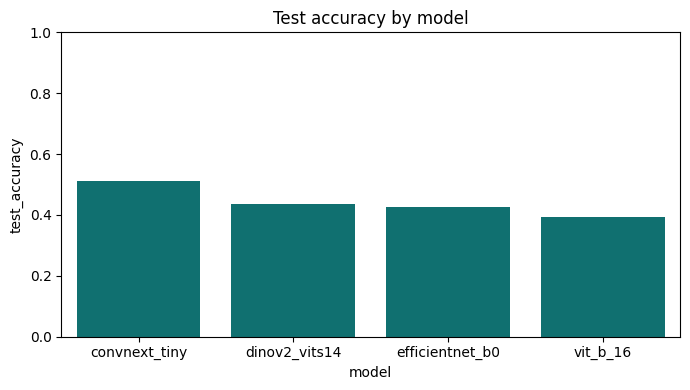

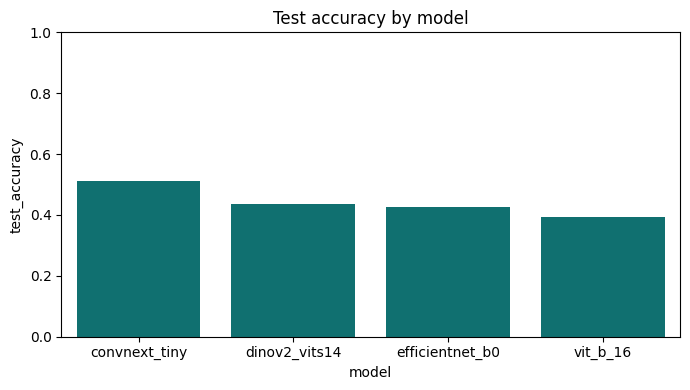

In [78]:
# Cell 15 - Compare final accuracies
summary_df = pd.DataFrame(
    [
        {
            "model": name,
            "test_accuracy": result["test_accuracy"],
        }
        for name, result in results.items()
    ]
).sort_values("test_accuracy", ascending=False)

display(summary_df)

plt.figure(figsize=(7, 4))
sns.barplot(data=summary_df, x="model", y="test_accuracy", color="teal")
plt.ylim(0, 1)
plt.title("Test accuracy by model")
plt.tight_layout()
plt.show()

os.makedirs("/content/drive/MyDrive/bhai_classification/outputs", exist_ok=True)

plt.figure(figsize=(7, 4))
sns.barplot(data=summary_df, x="model", y="test_accuracy", color="teal")
plt.ylim(0, 1)
plt.title("Test accuracy by model")
plt.tight_layout()
plt.savefig("/content/drive/MyDrive/bhai_classification/outputs/test_accuracy_by_model.png", dpi=300, bbox_inches="tight")
plt.show()




####################################################################################################
Model: efficientnet_b0
Accuracy: 0.4255

Per-class metrics:


,precision,recall,f1-score,support
M1,0.452381,0.463415,0.457831,41.0
M2,0.500000,0.405405,0.447761,37.0
M0,0.384615,0.416667,0.400000,12.0
M3,0.111111,0.250000,0.153846,4.0


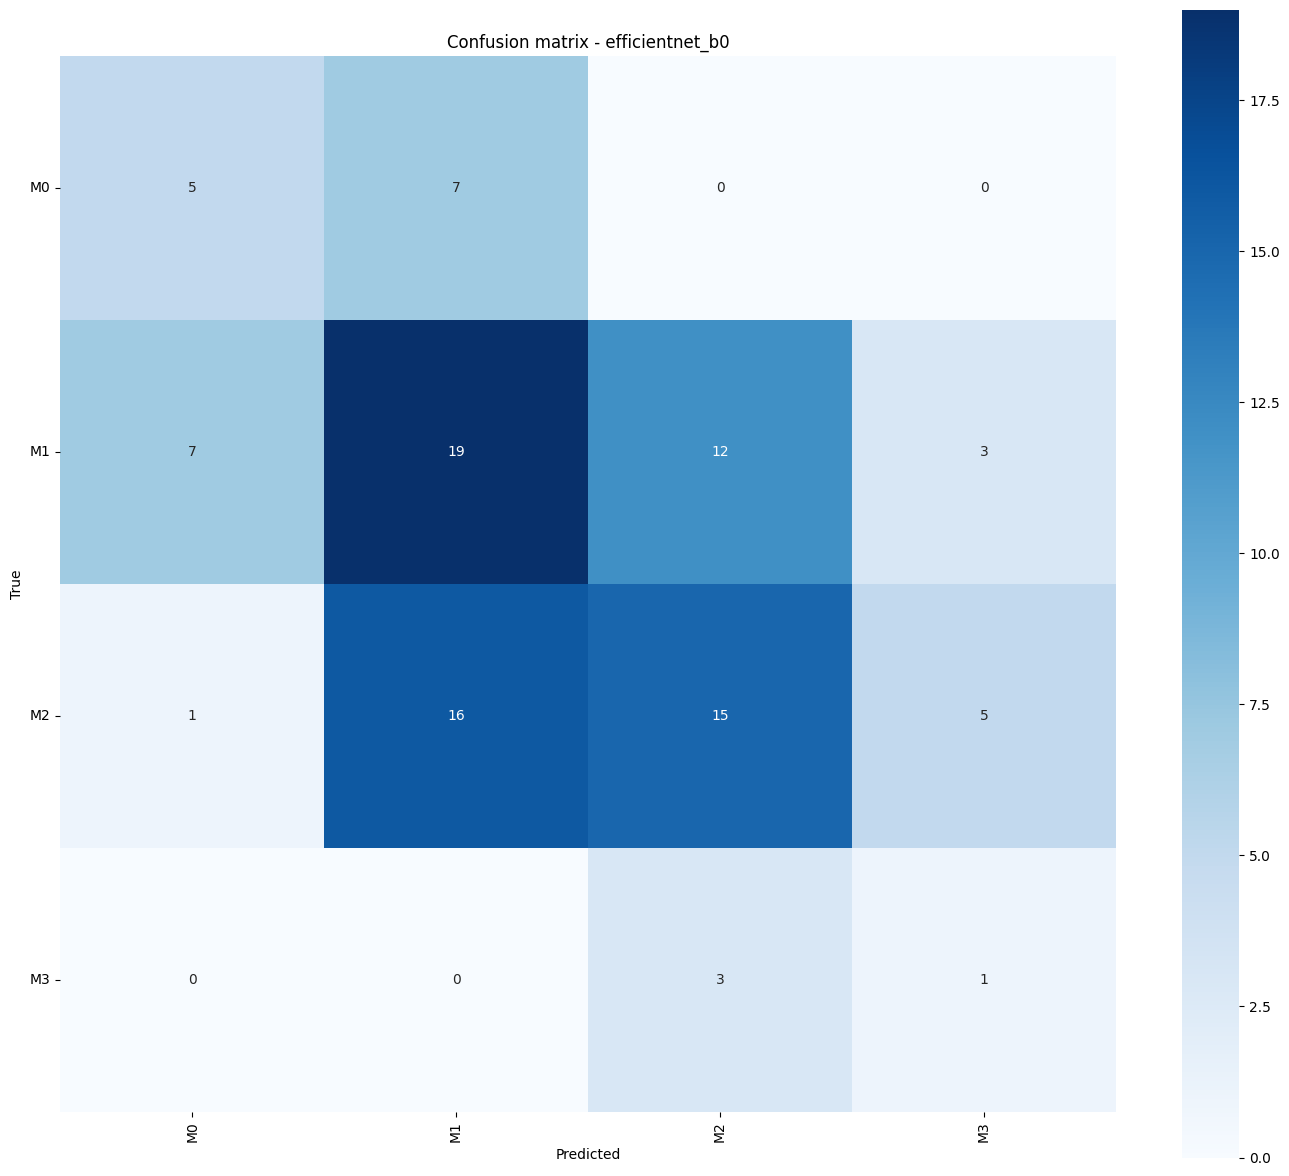


####################################################################################################
Model: convnext_tiny
Accuracy: 0.5106

Per-class metrics:


,precision,recall,f1-score,support
M2,0.642857,0.486486,0.553846,37.0
M1,0.500000,0.536585,0.517647,41.0
M0,0.350000,0.583333,0.437500,12.0
M3,0.500000,0.250000,0.333333,4.0


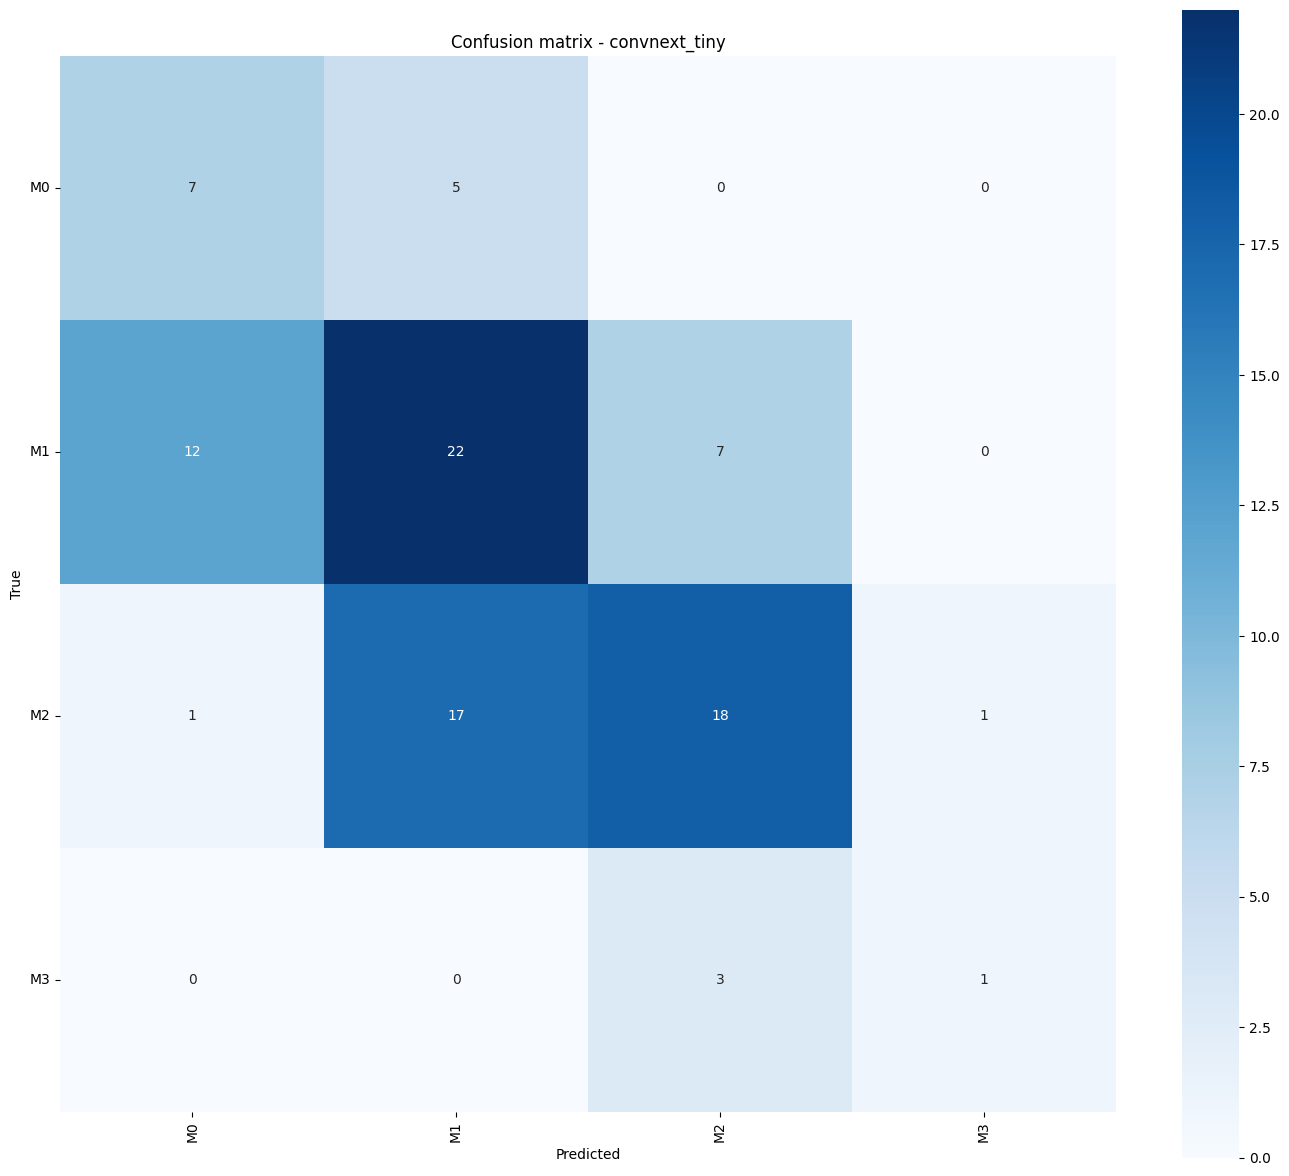


####################################################################################################
Model: vit_b_16
Accuracy: 0.3936

Per-class metrics:


,precision,recall,f1-score,support
M2,0.393617,1.0,0.564885,37.0
M0,0.000000,0.0,0.000000,12.0
M1,0.000000,0.0,0.000000,41.0
M3,0.000000,0.0,0.000000,4.0


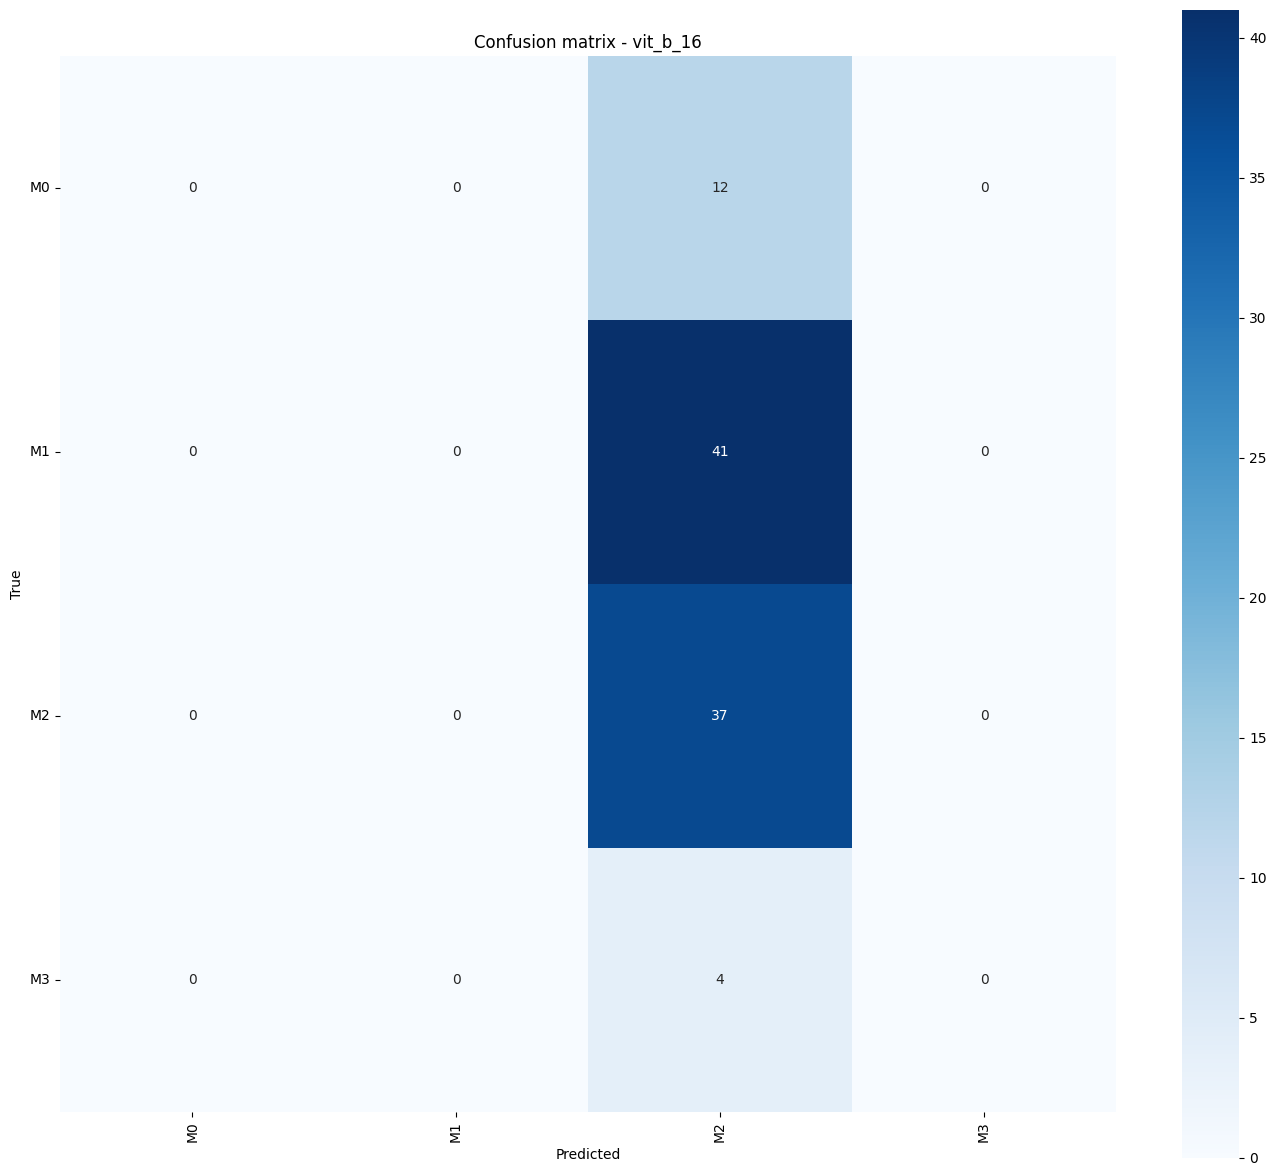


####################################################################################################
Model: dinov2_vits14
Accuracy: 0.4362

Per-class metrics:


,precision,recall,f1-score,support
M1,0.43617,1.0,0.607407,41.0
M0,0.00000,0.0,0.000000,12.0
M2,0.00000,0.0,0.000000,37.0
M3,0.00000,0.0,0.000000,4.0


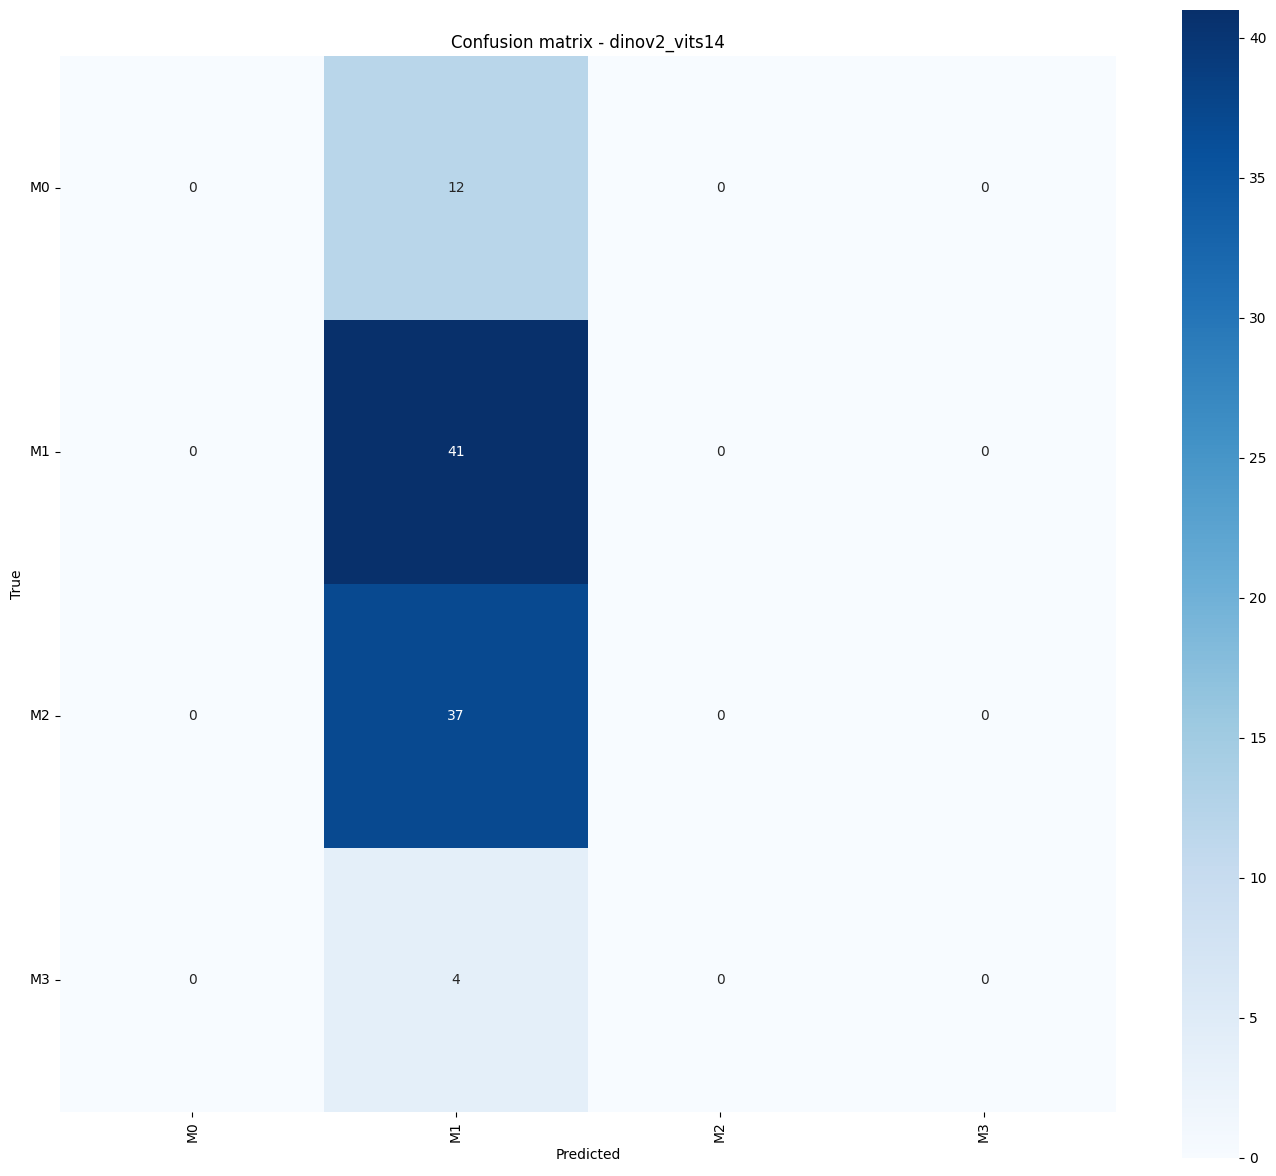

In [79]:
# Cell 16 - Per-class F1-score and confusion matrix for each model
def plot_confusion_matrix(cm, class_names, title, save_path=None):
    plt.figure(figsize=(14, 12))
    sns.heatmap(
        cm,
        cmap="Blues",
        square=True,
        cbar=True,
        xticklabels=class_names,
        yticklabels=class_names,
        annot=True,
        fmt="d"
    )
    plt.title(title)
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.xticks(rotation=90)
    plt.yticks(rotation=0)
    plt.tight_layout()

    if save_path is not None:
        plt.savefig(save_path, dpi=300, bbox_inches="tight")

    plt.show()


for model_name, result in results.items():
    print(f"\n{'#' * 100}")
    print(f"Model: {model_name}")
    print(f"Accuracy: {result['test_accuracy']:.4f}")

    report_df = result["classification_report_df"]
    per_class_f1 = (
        report_df.iloc[:num_classes][["precision", "recall", "f1-score", "support"]]
        .sort_values("f1-score", ascending=False)
    )

    print("\nPer-class metrics:")
    display(per_class_f1)

    plot_confusion_matrix(
        result["confusion_matrix"],
        classes,
        title=f"Confusion matrix - {model_name}",
        save_path=f"/content/drive/MyDrive/bhai_classification/outputs/{model_name}_confusion_matrix.png"
    )



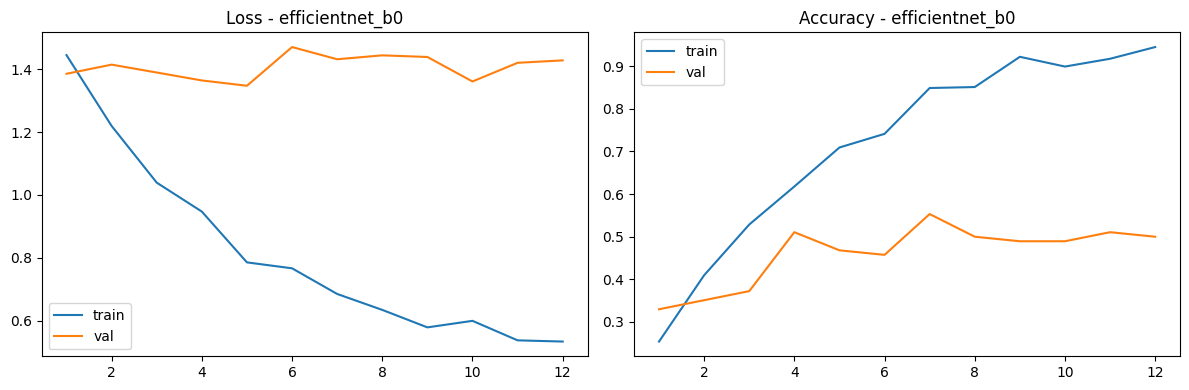

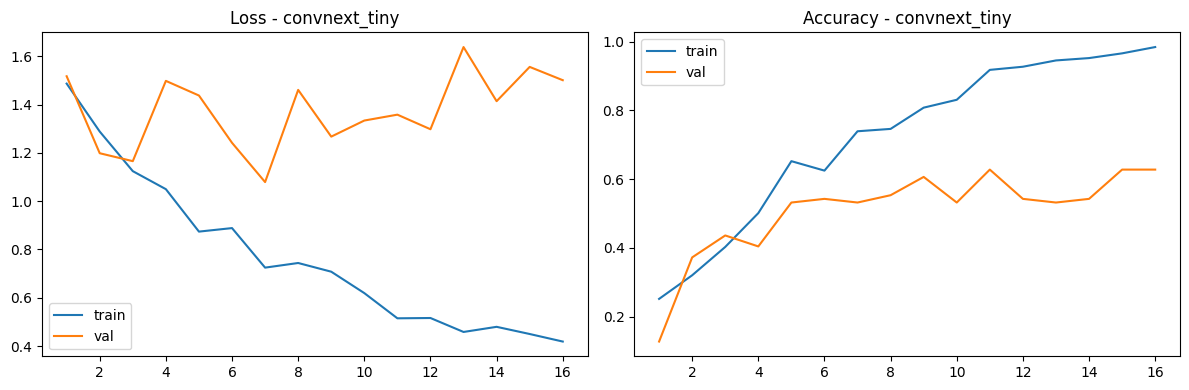

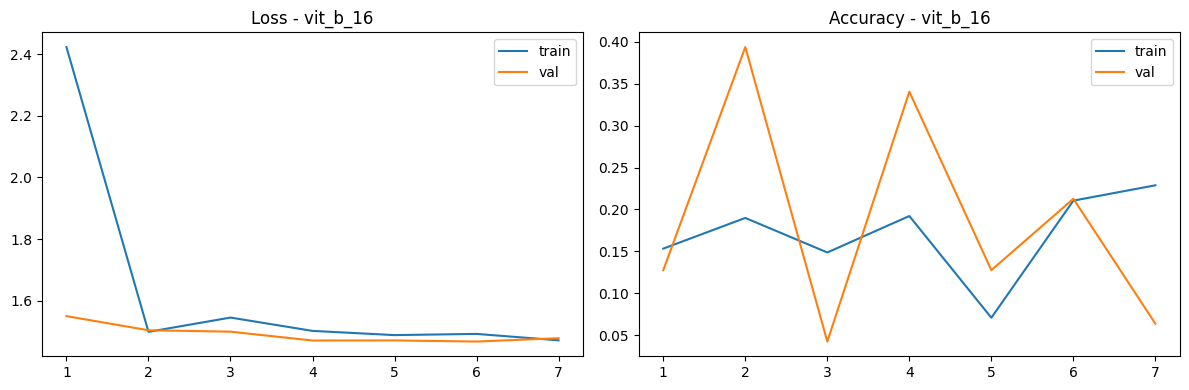

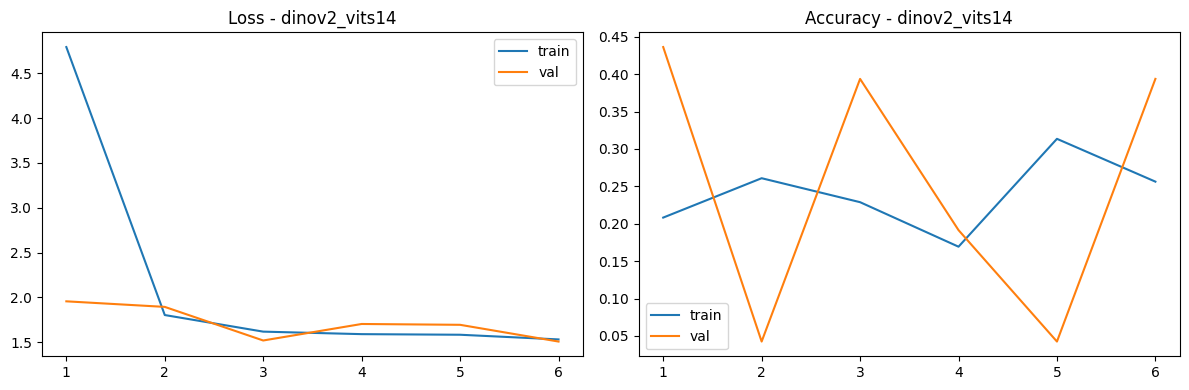

In [80]:
# Cell 17 - Optional: learning curves
for model_name, result in results.items():
    hist = result["history"]
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].plot(hist["epoch"], hist["train_loss"], label="train")
    axes[0].plot(hist["epoch"], hist["val_loss"], label="val")
    axes[0].set_title(f"Loss - {model_name}")
    axes[0].legend()

    axes[1].plot(hist["epoch"], hist["train_acc"], label="train")
    axes[1].plot(hist["epoch"], hist["val_acc"], label="val")
    axes[1].set_title(f"Accuracy - {model_name}")
    axes[1].legend()

    plt.tight_layout()
    plt.savefig(
        f"/content/drive/MyDrive/bhai_classification/outputs/{model_name}_learning_curves.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()

In [81]:
# Cell 18 - Optional: save results
os.makedirs("/content/drive/MyDrive/bhai_classification/outputs", exist_ok=True)
summary_df.to_csv("/content/drive/MyDrive/bhai_classification/outputs/model_summary.csv", index=False)

for model_name, result in results.items():
    result["classification_report_df"].to_csv(
        f"/content/drive/MyDrive/bhai_classification/outputs/{model_name}_classification_report.csv"
    )
    np.save(f"/content/drive/MyDrive/bhai_classification/outputs/{model_name}_confusion_matrix.npy", result["confusion_matrix"])

print("Saved outputs in /content/drive/MyDrive/bhai_classification/outputs")


Saved outputs in /content/drive/MyDrive/bhai_classification/outputs
